<a href="https://colab.research.google.com/github/itsanuragkumar/Safe_Pass-realmain/blob/main/MLprojectmain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
# save filepath to variable for easier access
file_path = '/content/test.csv'
# read the data and store data in DataFrame titled melbourne_data
df = pd.read_csv('/content/test.csv')
# print a summary of the data in Melbourne data
df.describe()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,11622.000000,13684.000000,13684.000000,13684.000000,13684.000000,13398.000000,13684.000000,13684.000000
mean,4268.421084,16.162672,23.713315,65.859836,20.944315,32.675698,32.257224,1478.366736
std,3226.322375,111.236393,131.924455,437.410829,14.619822,208.072727,5.101085,8542.801982
min,333.596667,0.000000,0.000000,1.000000,-5.000000,0.000000,20.509652,0.000000
25%,1650.781667,3.000000,4.000000,7.000000,10.000000,4.000000,28.053177,31.779454
50%,3143.796667,6.000000,6.000000,13.000000,18.000000,7.000000,32.249585,74.869250
75%,6098.132083,7.000000,7.000000,20.000000,28.000000,10.000000,36.405840,179.280882
max,14866.446667,1769.000000,1499.000000,5799.000000,67.000000,2593.000000,48.540663,82347.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13685 entries, 0 to 13684
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        13685 non-null  object 
 1   Customer_ID               13685 non-null  object 
 2   Month                     13684 non-null  object 
 3   Name                      12257 non-null  object 
 4   Age                       13684 non-null  object 
 5   SSN                       13684 non-null  object 
 6   Occupation                13684 non-null  object 
 7   Annual_Income             13684 non-null  object 
 8   Monthly_Inhand_Salary     11622 non-null  float64
 9   Num_Bank_Accounts         13684 non-null  float64
 10  Num_Credit_Card           13684 non-null  float64
 11  Interest_Rate             13684 non-null  float64
 12  Num_of_Loan               13684 non-null  object 
 13  Type_of_Loan              12096 non-null  object 
 14  Delay_

In [ ]:
df.shape


(50000, 27)

In [ ]:
df.isnull().sum()


,0
ID,0
Customer_ID,0
Month,1
Name,1428
Age,1
SSN,1
Occupation,1
Annual_Income,1
Monthly_Inhand_Salary,2063
Num_Bank_Accounts,1


In [ ]:
# Replacing the Null Values with mean values of the data using Simple Imputer
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan,strategy='mean',fill_value=None)
df['Monthly_Inhand_Salary']=imputer.fit_transform(df[['Monthly_Inhand_Salary']])
df['Num_of_Delayed_Payment']=imputer.fit_transform(df[['Num_of_Delayed_Payment']])
df['Num_Credit_Inquiries']=imputer.fit_transform(df[['Num_Credit_Inquiries']])
df['Amount_invested_monthly']=imputer.fit_transform(df[['Amount_invested_monthly']])
df['Monthly_Balance']=imputer.fit_transform(df[['Monthly_Balance']])

ValueError: Cannot use mean strategy with non-numeric data:
could not convert string to float: '2_'

In [ ]:
# lets see the unique values of columns
for col in df.columns:
    if df[col].dtype=='object':
        print()
        print(col)
        print(df[col].unique())


ID
['0x160a' '0x160b' '0x160c' ... '0xb65c' '0xb65d' '0xb666']

Customer_ID
['CUS_0xd40' 'CUS_0x21b1' 'CUS_0x2dbc' ... 'CUS_0x3911' 'CUS_0x2e7f'
 'CUS_0x1b02']

Month
['September' 'October' 'November' 'December' nan]

Name
['Aaron Maashoh' 'Rick Rothackerj' 'Langep' ... 'Alexei Oreskovicl'
 'Goldsteinm' 'Jones Lisag']

Age
['23' '24' '24_' '28' '35' '55' '22' '31' '32' '1694' '34' '30' '914' '45'
 '41_' '41' '33' '36' '39' '40' '40_' '37' '21' '46' '26' '27' '32_' '42'
 '42_' '20' '48' '49' '33_' '38' '38_' '44' '-500' '16' '17' '37_' '19_'
 '19' '3193' '43' '339' '14' '15' '25' '21_' '1203' '46_' '2823' '22_'
 '18' '47' '1643' '20_' '35_' '8327_' '29' '29_' '28_' '53' '56' '26_'
 '6586' '7014' '3391' '54' '3765' '43_' '18_' '47_' '4472' '50' '4022'
 '48_' '4576' '51' '52' '34_' '50_' '3355' '8034' '4610_' '27_' '31_'
 '7860' '36_' '2526' '45_' '3263' '4885' '51_' '39_' '25_' '694' '8288'
 '52_' '8404' '451' '3168' '5172' '8214' '4946' '3127' '55_' '7018' '2950'
 '7676' '5502' '4133' 

In [ ]:
import numpy as np
import pandas as pd

# Standardize 'Occupation' - replace '_______' and '_' with 'Unknown'
df['Occupation'] = df['Occupation'].replace(['_______', '_'], 'Others')

# Standardize 'Credit_Mix' - replace '_' with 'Unknown'
df['Credit_Mix'] = df['Credit_Mix'].replace('_', 'More')

# Standardize 'Payment_of_Min_Amount' - replace 'NM' with 'No'
df['Payment_of_Min_Amount'] = df['Payment_of_Min_Amount'].replace('NM', 'No')

# Standardize 'Payment_Behaviour' - replace '!@9#%8' with 'Unknown'
df['Payment_Behaviour'] = df['Payment_Behaviour'].replace('!@9#%8', 'Unknown')

# Refine 'Type_of_Loan' cleaning
def clean_type_of_loan(loan_str):
    if pd.isna(loan_str) or loan_str is None:
        return np.nan
    # Remove 'and Not Specified' and strip extra spaces
    cleaned_str = str(loan_str).replace('and Not Specified', '').strip()
    # Split by comma, remove leading/trailing spaces, filter out empty strings
    loan_types = [loan.strip() for loan in cleaned_str.split(',') if loan.strip() != '']
    # Remove duplicates and sort for consistent representation
    return ', '.join(sorted(list(set(loan_types))))

df['Type_of_Loan'] = df['Type_of_Loan'].apply(clean_type_of_loan)

print("Unique values after cleaning:")
for col in ['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Type_of_Loan']:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].unique())

display(df.head())

Unique values after cleaning:

Occupation:
['Scientist' 'Others' 'Teacher' 'Engineer' 'Entrepreneur' 'Developer'
 'Lawyer' 'Media_Manager' 'Doctor' 'Journalist' 'Manager' 'Accountant'
 'Musician' 'Mechanic' 'Writer' 'Architect' nan]

Credit_Mix:
['Good' 'More' 'Standard' 'Bad' nan]

Payment_of_Min_Amount:
['No' 'Yes' nan]

Payment_Behaviour:
['Low_spent_Small_value_payments' 'High_spent_Medium_value_payments'
 'Low_spent_Medium_value_payments' 'High_spent_Large_value_payments'
 'Low_spent_Large_value_payments' 'Unknown'
 'High_spent_Small_value_payments' nan]

Type_of_Loan:
['Auto Loan, Credit-Builder Loan, Personal Loan, and Home Equity Loan'
 'Credit-Builder Loan' 'Auto Loan' ...
 'Debt Consolidation Loan, Payday Loan, Student Loan, and Student Loan'
 'Credit-Builder Loan, Personal Loan, Student Loan, and Credit-Builder Loan'
 'Auto Loan, Home Equity Loan, Mortgage Loan, Payday Loan, and Credit-Builder Loan']


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
0,0x160a,CUS_0xd40,September,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,2022.0,Good,809.98,35.030402,22 Years and 9 Months,No,49.574949,236.64268203272135,Low_spent_Small_value_payments,186.26670208571772
1,0x160b,CUS_0xd40,October,Aaron Maashoh,24,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,4.0,Good,809.98,33.053114,22 Years and 10 Months,No,49.574949,21.465380264657146,High_spent_Medium_value_payments,361.44400385378196
2,0x160c,CUS_0xd40,November,Aaron Maashoh,24,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,4.0,Good,809.98,33.811894,NaN,No,49.574949,148.23393788500925,Low_spent_Medium_value_payments,264.67544623342997
3,0x160d,CUS_0xd40,December,Aaron Maashoh,24_,821-00-0265,Scientist,19114.12,4268.421084,3.0,...,4.0,Good,809.98,32.430559,23 Years and 0 Months,No,49.574949,39.08251089460281,High_spent_Medium_value_payments,343.82687322383634
4,0x1616,CUS_0x21b1,September,Rick Rothackerj,28,004-07-5839,Others,34847.84,3037.986667,2.0,...,5.0,Good,605.03,25.926822,27 Years and 3 Months,No,18.816215,39.684018417945296,High_spent_Large_value_payments,485.2984336755923


In [ ]:
for col in df.columns:
    if df[col].dtype=='object':
        print()
        print(col)
        print(df[col].unique())


ID
['0x160a' '0x160b' '0x160c' ... '0xb65c' '0xb65d' '0xb666']

Customer_ID
['CUS_0xd40' 'CUS_0x21b1' 'CUS_0x2dbc' ... 'CUS_0x3911' 'CUS_0x2e7f'
 'CUS_0x1b02']

Month
['September' 'October' 'November' 'December' nan]

Name
['Aaron Maashoh' 'Rick Rothackerj' 'Langep' ... 'Alexei Oreskovicl'
 'Goldsteinm' 'Jones Lisag']

Age
['23' '24' '24_' '28' '35' '55' '22' '31' '32' '1694' '34' '30' '914' '45'
 '41_' '41' '33' '36' '39' '40' '40_' '37' '21' '46' '26' '27' '32_' '42'
 '42_' '20' '48' '49' '33_' '38' '38_' '44' '-500' '16' '17' '37_' '19_'
 '19' '3193' '43' '339' '14' '15' '25' '21_' '1203' '46_' '2823' '22_'
 '18' '47' '1643' '20_' '35_' '8327_' '29' '29_' '28_' '53' '56' '26_'
 '6586' '7014' '3391' '54' '3765' '43_' '18_' '47_' '4472' '50' '4022'
 '48_' '4576' '51' '52' '34_' '50_' '3355' '8034' '4610_' '27_' '31_'
 '7860' '36_' '2526' '45_' '3263' '4885' '51_' '39_' '25_' '694' '8288'
 '52_' '8404' '451' '3168' '5172' '8214' '4946' '3127' '55_' '7018' '2950'
 '7676' '5502' '4133' 

In [ ]:
import plotly.express as px
import matplotlib.pyplot as plt


In [ ]:
px.pie(df.groupby('Occupation',as_index=False)['ID'].count(),values='ID',names='Occupation',labels={'ID':'Count'},template='plotly_dark',color_discrete_sequence=px.colors.sequential.Plasma,hole=.5,title='<b>Distribution of Customers by Occupation</b>')

In [ ]:
px.pie(df.groupby('Payment_of_Min_Amount',as_index=False)['ID'].count(),values='ID',names='Payment_of_Min_Amount',labels={'ID':'Count'},template='plotly_dark',color_discrete_sequence=px.colors.sequential.Plasma,hole=.5,title='<b>Distribution of Customers by Payment of Minimum Amount</b>')

In [ ]:
px.pie(df.groupby('Payment_Behaviour',as_index=False)['ID'].count(),values='ID',names='Payment_Behaviour',labels={'ID':'Count'},template='plotly_dark',color_discrete_sequence=px.colors.sequential.Plasma,hole=.5,title='<b>Distribution of Customers by Payment_Behaviour</b>')

In [ ]:
px.box(df,x='Occupation',y='Monthly_Inhand_Salary',color='Occupation',template='plotly_dark',title='<b>Monthly In-hand Salary Distribution by Occupation</b>')

In [ ]:
px.box(df,x='Payment_of_Min_Amount',y='Monthly_Inhand_Salary',color='Payment_of_Min_Amount',template='plotly_dark',title='<b>Monthly In-hand Salary Distribution by Payment_of_Min_Amount</b>')

In [ ]:
px.box(df,x='Payment_Behaviour',y='Monthly_Inhand_Salary',color='Payment_Behaviour',template='plotly_dark',title='<b>Monthly In-hand Salary Distribution by Payment_Behaviour</b>')

In [ ]:
px.scatter(df, x='Monthly_Inhand_Salary', y='Total_EMI_per_month', color='Credit_Mix', size='Num_Credit_Inquiries', labels={'Monthly_Inhand_Salary':'Monthly In-hand Salary', 'Total_EMI_per_month':'Total EMI per Month', 'Num_Credit_Inquiries':'Number of Credit Inquiries'}, template='plotly_dark', title='<b>Monthly In-hand Salary vs. Total EMI per Month by Credit Mix</b>')

In [ ]:
px.scatter(df, x='Interest_Rate', y='Credit_Utilization_Ratio', color='Occupation', size='Num_Credit_Card', labels={'Interest_Rate':'Interest Rate', 'Credit_Utilization_Ratio':'Credit Utilization Ratio', 'Num_Credit_Card':'Number of Credit Cards'}, template='plotly_dark', title='<b>Interest Rate vs. Credit Utilization Ratio by Occupation</b>')

In [ ]:
px.box(df, x='Credit_Mix', y='Interest_Rate', color='Payment_of_Min_Amount', labels={'Credit_Mix':'Credit Mix', 'Interest_Rate':'Interest Rate', 'Payment_of_Min_Amount':'Payment of Minimum Amount'}, template='plotly_dark', title='<b>Interest Rate Distribution by Credit Mix and Minimum Payment Status</b>')

In [ ]:
print(df.columns.tolist())

['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance']


In [ ]:
!pip install scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import (
    LogisticRegression,
    LinearRegression,
    RidgeClassifier,
    BayesianRidge,
    HuberRegressor
)

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 13685
Columns: 27


In [ ]:
print(df.columns.tolist())

['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance']


In [ ]:
df.isnull().sum()


,0
ID,0
Customer_ID,0
Month,1
Name,1428
Age,1
SSN,1
Occupation,1
Annual_Income,1
Monthly_Inhand_Salary,0
Num_Bank_Accounts,1


In [ ]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])

print(numeric_df.shape)
numeric_df.head()

(13685, 8)


,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
0,1824.843333,3.0,4.0,3.0,3.0,2022.0,35.030402,49.574949
1,1824.843333,3.0,4.0,3.0,3.0,4.0,33.053114,49.574949
2,1824.843333,3.0,4.0,3.0,-1.0,4.0,33.811894,49.574949
3,4268.421084,3.0,4.0,3.0,4.0,4.0,32.430559,49.574949
4,3037.986667,2.0,4.0,6.0,3.0,5.0,25.926822,18.816215


In [ ]:
numeric_df = numeric_df.dropna()

print(numeric_df.shape)

(13398, 8)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(numeric_df)

print(X_scaled.shape)

(13398, 8)


In [ ]:
from sklearn.cluster import KMeans

In [ ]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

In [ ]:
numeric_df['Cluster'] = clusters

numeric_df.head()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month,Cluster
0,1824.843333,3.0,4.0,3.0,3.0,2022.0,35.030402,49.574949,1
1,1824.843333,3.0,4.0,3.0,3.0,4.0,33.053114,49.574949,1
2,1824.843333,3.0,4.0,3.0,-1.0,4.0,33.811894,49.574949,1
3,4268.421084,3.0,4.0,3.0,4.0,4.0,32.430559,49.574949,1
4,3037.986667,2.0,4.0,6.0,3.0,5.0,25.926822,18.816215,1


In [ ]:
import matplotlib.pyplot as plt

inertia = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

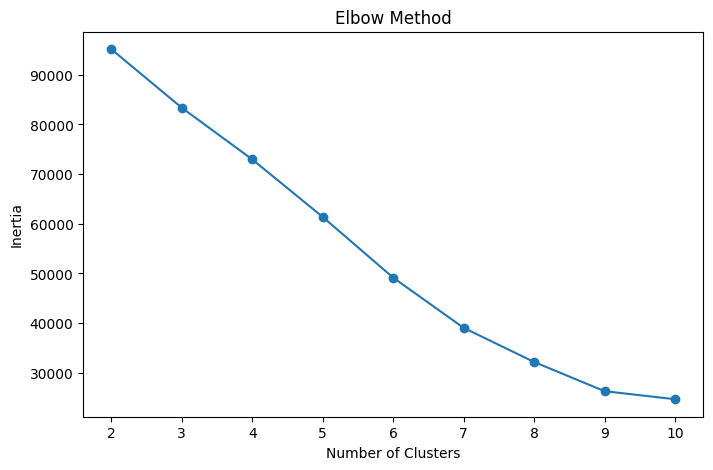

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

silhouette = silhouette_score(
    X_scaled,
    clusters
)

print("Silhouette Score:", silhouette)

Silhouette Score: 0.6147114111172343


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)

(13398, 2)


In [ ]:
print(pca.explained_variance_ratio_)


[0.1656017 0.1272853]


In [ ]:
print(
    "Total explained variance:",
    sum(pca.explained_variance_ratio_)
)

Total explained variance: 0.29288699435414567


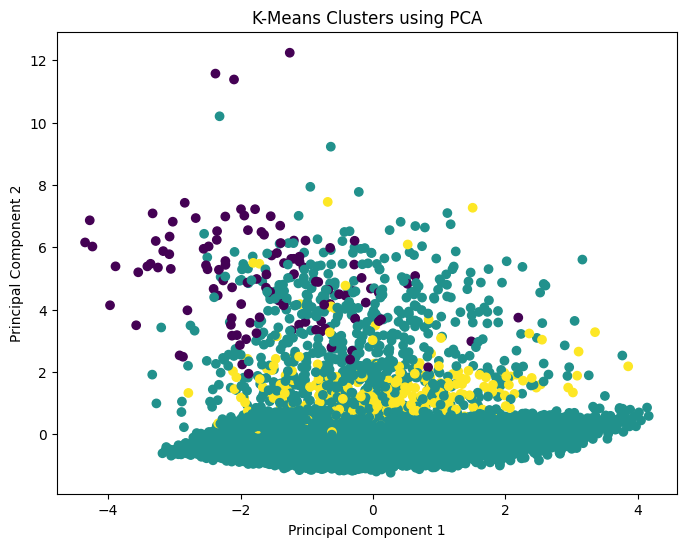

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters using PCA")

plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering

In [ ]:
hierarchical = AgglomerativeClustering(
    n_clusters=3
)

hierarchical_clusters = hierarchical.fit_predict(
    X_scaled
)

In [ ]:
print(pd.Series(hierarchical_clusters).value_counts())

0    13054
1      239
2      105
Name: count, dtype: int64


In [ ]:
hierarchical_score = silhouette_score(
    X_scaled,
    hierarchical_clusters
)

print(
    "Hierarchical Clustering Silhouette Score:",
    hierarchical_score
)

Hierarchical Clustering Silhouette Score: 0.639855007372776


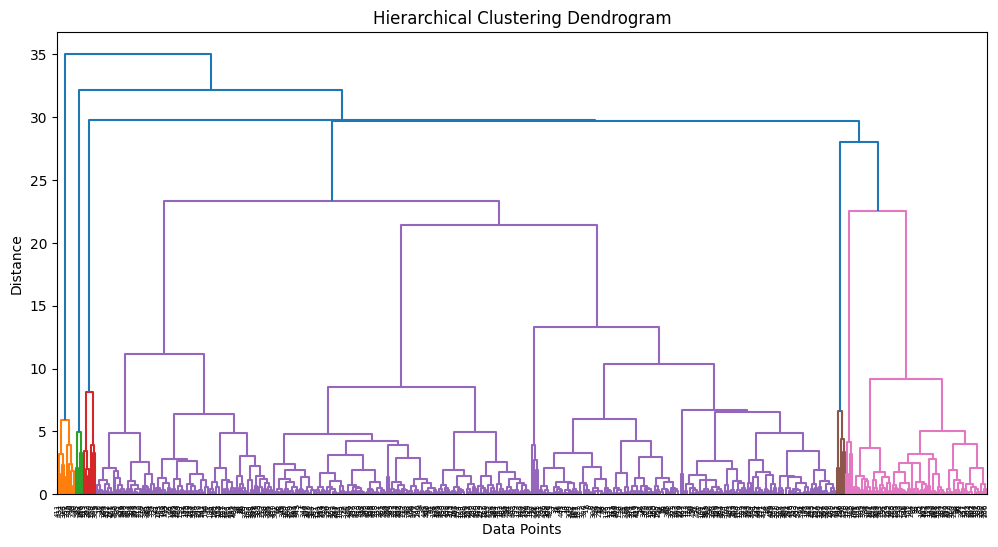

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_matrix = linkage(
    X_scaled[:500],
    method='ward'
)

plt.figure(figsize=(12,6))

dendrogram(linkage_matrix)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()